In [1]:
import numpy as np
import pandas as pd
from sklearn import datasets
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegressionCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
)

# ---------------------------------------------------------
# 1. Load Data
# ---------------------------------------------------------
cancer_dataset = datasets.load_breast_cancer()
X = cancer_dataset.data
y = cancer_dataset.target
feature_names = cancer_dataset.feature_names

# ---------------------------------------------------------
# 2. Settings & Models
# ---------------------------------------------------------
n_splits = 5           
random_state = 42

models = {
    'k-NN (k=99)': KNeighborsClassifier(n_neighbors=99),
    
    'DecisionTree (max_depth=3)': Pipeline([
        ('scaler', StandardScaler()),
        ('dt', DecisionTreeClassifier(max_depth=3, random_state=random_state))
    ]),
    
    'SVM (linear, C=1.0)': SVC(kernel='linear', C=1.0, probability=False)
}

skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)

# ---------------------------------------------------------
# 3. Cross-Validation with Feature Selection
# ---------------------------------------------------------
print("=== Evaluating Models with Per-Fold LASSO Feature Selection ===")

total_feature_selections = np.zeros(len(feature_names))

for model_name, model in models.items():
    print(f"\n============================================================")
    print(f"Evaluating Model: {model_name}")
    print(f"============================================================")
    
    # Initialize lists to track all metrics
    train_accs, test_accs = [], []
    train_precs, test_precs = [], []
    train_recs, test_recs = [], []
    train_f1s, test_f1s = [], []
    
    for fold_idx, (train_index, test_index) in enumerate(skf.split(X, y)):
        fold_num = fold_idx + 1
        
        X_train, X_test = X[train_index], X[test_index]
        y_train, y_test = y[train_index], y[test_index]

        scaler = StandardScaler()
        X_train_scaled = scaler.fit_transform(X_train)
        X_test_scaled = scaler.transform(X_test)

        lasso_selector = LogisticRegressionCV(
            cv=3, 
            penalty='l1', 
            solver='liblinear', 
            random_state=random_state,
            max_iter=10000 
        )
        lasso_selector.fit(X_train_scaled, y_train)

        selected_indices = np.where(lasso_selector.coef_[0] != 0)[0]
        selected_feature_names_in_fold = feature_names[selected_indices]

        if len(selected_indices) == 0:
            print(f"  [Warning] Fold {fold_num}: LASSO removed all features. Using all features as fallback.")
            selected_indices = np.arange(X.shape[1])
            selected_feature_names_in_fold = feature_names
            
        if model_name == list(models.keys())[0]: 
             total_feature_selections[selected_indices] += 1

        X_train_sel = X_train_scaled[:, selected_indices]
        X_test_sel = X_test_scaled[:, selected_indices]

        model.fit(X_train_sel, y_train)
        
        y_train_pred = model.predict(X_train_sel)
        y_test_pred = model.predict(X_test_sel)

        # Calculate all metrics (using zero_division=0 to prevent warnings if a class isn't predicted)
        train_acc = accuracy_score(y_train, y_train_pred)
        test_acc = accuracy_score(y_test, y_test_pred)
        
        train_prec = precision_score(y_train, y_train_pred, zero_division=0)
        test_prec = precision_score(y_test, y_test_pred, zero_division=0)
        
        train_rec = recall_score(y_train, y_train_pred, zero_division=0)
        test_rec = recall_score(y_test, y_test_pred, zero_division=0)
        
        train_f1 = f1_score(y_train, y_train_pred, zero_division=0)
        test_f1 = f1_score(y_test, y_test_pred, zero_division=0)
        
        # Append to lists
        train_accs.append(train_acc)
        test_accs.append(test_acc)
        train_precs.append(train_prec)
        test_precs.append(test_prec)
        train_recs.append(train_rec)
        test_recs.append(test_rec)
        train_f1s.append(train_f1)
        test_f1s.append(test_f1)
        
        cm_train = confusion_matrix(y_train, y_train_pred)
        cm_test = confusion_matrix(y_test, y_test_pred)

        print(f"\n--- Fold {fold_num} ---")
        print(f"  Total Features Selected: {len(selected_indices)} / {X.shape[1]}")
        print(f"  Selected Feature Names : {', '.join(selected_feature_names_in_fold)}")
        print(f"  Train Metrics -> Acc: {train_acc:.4f} | Prec: {train_prec:.4f} | Rec: {train_rec:.4f} | F1: {train_f1:.4f}")
        print(f"  Test Metrics  -> Acc: {test_acc:.4f} | Prec: {test_prec:.4f} | Rec: {test_rec:.4f} | F1: {test_f1:.4f}")
        print("  Test Confusion Matrix:\n", cm_test)

    # Print Overall Summary across all metrics
    print(f"\n*** Overall Summary for {model_name} ***")
    print(f"  Train Accuracy  : {np.mean(train_accs):.4f} ± {np.std(train_accs):.4f}")
    print(f"  Test Accuracy   : {np.mean(test_accs):.4f} ± {np.std(test_accs):.4f}")
    print(f"  Train Precision : {np.mean(train_precs):.4f} ± {np.std(train_precs):.4f}")
    print(f"  Test Precision  : {np.mean(test_precs):.4f} ± {np.std(test_precs):.4f}")
    print(f"  Train Recall    : {np.mean(train_recs):.4f} ± {np.std(train_recs):.4f}")
    print(f"  Test Recall     : {np.mean(test_recs):.4f} ± {np.std(test_recs):.4f}")
    print(f"  Train F1-Score  : {np.mean(train_f1s):.4f} ± {np.std(train_f1s):.4f}")
    print(f"  Test F1-Score   : {np.mean(test_f1s):.4f} ± {np.std(test_f1s):.4f}")

# ---------------------------------------------------------
# 4. Feature Stability Report
# ---------------------------------------------------------
print("\n============================================================")
print("LASSO Feature Stability Across Folds")
print("============================================================")
for name, count in zip(feature_names, total_feature_selections):
    if count > 0:
        print(f"{name:<25}: selected in {int(count)}/{n_splits} folds")

=== Evaluating Models with Per-Fold LASSO Feature Selection ===

Evaluating Model: k-NN (k=99)

--- Fold 1 ---
  Total Features Selected: 4 / 30
  Selected Feature Names : mean concave points, worst radius, worst texture, worst concave points
  Train Metrics -> Acc: 0.9538 | Prec: 0.9344 | Rec: 0.9965 | F1: 0.9645
  Test Metrics  -> Acc: 0.9825 | Prec: 0.9726 | Rec: 1.0000 | F1: 0.9861
  Test Confusion Matrix:
 [[41  2]
 [ 0 71]]

--- Fold 2 ---
  Total Features Selected: 10 / 30
  Selected Feature Names : mean concavity, mean concave points, radius error, worst radius, worst texture, worst area, worst smoothness, worst concavity, worst concave points, worst symmetry
  Train Metrics -> Acc: 0.9451 | Prec: 0.9196 | Rec: 1.0000 | F1: 0.9581
  Test Metrics  -> Acc: 0.9123 | Prec: 0.8961 | Rec: 0.9718 | F1: 0.9324
  Test Confusion Matrix:
 [[35  8]
 [ 2 69]]

--- Fold 3 ---
  Total Features Selected: 30 / 30
  Selected Feature Names : mean radius, mean texture, mean perimeter, mean area, m

In [4]:
import numpy as np
import pandas as pd
from sklearn import datasets
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegressionCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
)

# ---------------------------------------------------------
# 1. Load Data
# ---------------------------------------------------------
cancer_dataset = datasets.load_breast_cancer()
X = cancer_dataset.data
y = cancer_dataset.target
feature_names = cancer_dataset.feature_names

# ---------------------------------------------------------
# 2. Settings & Models
# ---------------------------------------------------------
n_splits = 8           
random_state = 42

models = {
    'k-NN (k=99)': KNeighborsClassifier(n_neighbors=99),
    
    'DecisionTree (max_depth=3)': Pipeline([
        ('scaler', StandardScaler()),
        ('dt', DecisionTreeClassifier(max_depth=3, random_state=random_state))
    ]),
    
    'SVM (linear, C=1.0)': SVC(kernel='linear', C=1.0, probability=False)
}

skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)

# ---------------------------------------------------------
# 3. Cross-Validation with Feature Selection
# ---------------------------------------------------------
print("=== Evaluating Models with Per-Fold LASSO Feature Selection ===")

total_feature_selections = np.zeros(len(feature_names))

for model_name, model in models.items():
    print(f"\n============================================================")
    print(f"Evaluating Model: {model_name}")
    print(f"============================================================")
    
    # Initialize lists to track all metrics
    train_accs, test_accs = [], []
    train_precs, test_precs = [], []
    train_recs, test_recs = [], []
    train_f1s, test_f1s = [], []
    
    for fold_idx, (train_index, test_index) in enumerate(skf.split(X, y)):
        fold_num = fold_idx + 1
        
        X_train, X_test = X[train_index], X[test_index]
        y_train, y_test = y[train_index], y[test_index]

        scaler = StandardScaler()
        X_train_scaled = scaler.fit_transform(X_train)
        X_test_scaled = scaler.transform(X_test)

        lasso_selector = LogisticRegressionCV(
            cv=3, 
            penalty='l1', 
            solver='liblinear', 
            random_state=random_state,
            max_iter=10000 
        )
        lasso_selector.fit(X_train_scaled, y_train)

        selected_indices = np.where(lasso_selector.coef_[0] != 0)[0]
        selected_feature_names_in_fold = feature_names[selected_indices]

        if len(selected_indices) == 0:
            print(f"  [Warning] Fold {fold_num}: LASSO removed all features. Using all features as fallback.")
            selected_indices = np.arange(X.shape[1])
            selected_feature_names_in_fold = feature_names
            
        if model_name == list(models.keys())[0]: 
             total_feature_selections[selected_indices] += 1

        X_train_sel = X_train_scaled[:, selected_indices]
        X_test_sel = X_test_scaled[:, selected_indices]

        model.fit(X_train_sel, y_train)
        
        y_train_pred = model.predict(X_train_sel)
        y_test_pred = model.predict(X_test_sel)

        # Calculate all metrics (using zero_division=0 to prevent warnings if a class isn't predicted)
        train_acc = accuracy_score(y_train, y_train_pred)
        test_acc = accuracy_score(y_test, y_test_pred)
        
        train_prec = precision_score(y_train, y_train_pred, zero_division=0)
        test_prec = precision_score(y_test, y_test_pred, zero_division=0)
        
        train_rec = recall_score(y_train, y_train_pred, zero_division=0)
        test_rec = recall_score(y_test, y_test_pred, zero_division=0)
        
        train_f1 = f1_score(y_train, y_train_pred, zero_division=0)
        test_f1 = f1_score(y_test, y_test_pred, zero_division=0)
        
        # Append to lists
        train_accs.append(train_acc)
        test_accs.append(test_acc)
        train_precs.append(train_prec)
        test_precs.append(test_prec)
        train_recs.append(train_rec)
        test_recs.append(test_rec)
        train_f1s.append(train_f1)
        test_f1s.append(test_f1)
        
        cm_train = confusion_matrix(y_train, y_train_pred)
        cm_test = confusion_matrix(y_test, y_test_pred)

        print(f"\n--- Fold {fold_num} ---")
        print(f"  Total Features Selected: {len(selected_indices)} / {X.shape[1]}")
        print(f"  Selected Feature Names : {', '.join(selected_feature_names_in_fold)}")
        print(f"  Train Metrics -> Acc: {train_acc:.4f} | Prec: {train_prec:.4f} | Rec: {train_rec:.4f} | F1: {train_f1:.4f}")
        print(f"  Test Metrics  -> Acc: {test_acc:.4f} | Prec: {test_prec:.4f} | Rec: {test_rec:.4f} | F1: {test_f1:.4f}")
        print("  Test Confusion Matrix:\n", cm_test)

    # Print Overall Summary across all metrics
    print(f"\n*** Overall Summary for {model_name} ***")
    print(f"  Train Accuracy  : {np.mean(train_accs):.4f} ± {np.std(train_accs):.4f}")
    print(f"  Test Accuracy   : {np.mean(test_accs):.4f} ± {np.std(test_accs):.4f}")
    print(f"  Train Precision : {np.mean(train_precs):.4f} ± {np.std(train_precs):.4f}")
    print(f"  Test Precision  : {np.mean(test_precs):.4f} ± {np.std(test_precs):.4f}")
    print(f"  Train Recall    : {np.mean(train_recs):.4f} ± {np.std(train_recs):.4f}")
    print(f"  Test Recall     : {np.mean(test_recs):.4f} ± {np.std(test_recs):.4f}")
    print(f"  Train F1-Score  : {np.mean(train_f1s):.4f} ± {np.std(train_f1s):.4f}")
    print(f"  Test F1-Score   : {np.mean(test_f1s):.4f} ± {np.std(test_f1s):.4f}")

# ---------------------------------------------------------
# 4. Feature Stability Report
# ---------------------------------------------------------
print("\n============================================================")
print("LASSO Feature Stability Across Folds")
print("============================================================")
for name, count in zip(feature_names, total_feature_selections):
    if count > 0:
        print(f"{name:<25}: selected in {int(count)}/{n_splits} folds")

=== Evaluating Models with Per-Fold LASSO Feature Selection ===

Evaluating Model: k-NN (k=99)

--- Fold 1 ---
  Total Features Selected: 11 / 30
  Selected Feature Names : mean concave points, radius error, compactness error, fractal dimension error, worst radius, worst texture, worst area, worst smoothness, worst concavity, worst concave points, worst symmetry
  Train Metrics -> Acc: 0.9396 | Prec: 0.9196 | Rec: 0.9904 | F1: 0.9537
  Test Metrics  -> Acc: 0.9722 | Prec: 0.9574 | Rec: 1.0000 | F1: 0.9783
  Test Confusion Matrix:
 [[25  2]
 [ 0 45]]

--- Fold 2 ---
  Total Features Selected: 20 / 30
  Selected Feature Names : mean texture, mean smoothness, mean compactness, mean concavity, mean concave points, radius error, texture error, smoothness error, compactness error, concavity error, concave points error, symmetry error, fractal dimension error, worst radius, worst texture, worst area, worst concavity, worst concave points, worst symmetry, worst fractal dimension
  Train Metric

In [5]:
import numpy as np
import pandas as pd
from sklearn import datasets
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegressionCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
)

# ---------------------------------------------------------
# 1. Load Data
# ---------------------------------------------------------
cancer_dataset = datasets.load_breast_cancer()
X = cancer_dataset.data
y = cancer_dataset.target
feature_names = cancer_dataset.feature_names

# ---------------------------------------------------------
# 2. Settings & Models
# ---------------------------------------------------------
n_splits = 10          
random_state = 42

models = {
    'k-NN (k=99)': KNeighborsClassifier(n_neighbors=99),
    
    'DecisionTree (max_depth=3)': Pipeline([
        ('scaler', StandardScaler()),
        ('dt', DecisionTreeClassifier(max_depth=3, random_state=random_state))
    ]),
    
    'SVM (linear, C=1.0)': SVC(kernel='linear', C=1.0, probability=False)
}

skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)

# ---------------------------------------------------------
# 3. Cross-Validation with Feature Selection
# ---------------------------------------------------------
print("=== Evaluating Models with Per-Fold LASSO Feature Selection ===")

total_feature_selections = np.zeros(len(feature_names))

for model_name, model in models.items():
    print(f"\n============================================================")
    print(f"Evaluating Model: {model_name}")
    print(f"============================================================")
    
    # Initialize lists to track all metrics
    train_accs, test_accs = [], []
    train_precs, test_precs = [], []
    train_recs, test_recs = [], []
    train_f1s, test_f1s = [], []
    
    for fold_idx, (train_index, test_index) in enumerate(skf.split(X, y)):
        fold_num = fold_idx + 1
        
        X_train, X_test = X[train_index], X[test_index]
        y_train, y_test = y[train_index], y[test_index]

        scaler = StandardScaler()
        X_train_scaled = scaler.fit_transform(X_train)
        X_test_scaled = scaler.transform(X_test)

        lasso_selector = LogisticRegressionCV(
            cv=3, 
            penalty='l1', 
            solver='liblinear', 
            random_state=random_state,
            max_iter=10000 
        )
        lasso_selector.fit(X_train_scaled, y_train)

        selected_indices = np.where(lasso_selector.coef_[0] != 0)[0]
        selected_feature_names_in_fold = feature_names[selected_indices]

        if len(selected_indices) == 0:
            print(f"  [Warning] Fold {fold_num}: LASSO removed all features. Using all features as fallback.")
            selected_indices = np.arange(X.shape[1])
            selected_feature_names_in_fold = feature_names
            
        if model_name == list(models.keys())[0]: 
             total_feature_selections[selected_indices] += 1

        X_train_sel = X_train_scaled[:, selected_indices]
        X_test_sel = X_test_scaled[:, selected_indices]

        model.fit(X_train_sel, y_train)
        
        y_train_pred = model.predict(X_train_sel)
        y_test_pred = model.predict(X_test_sel)

        # Calculate all metrics (using zero_division=0 to prevent warnings if a class isn't predicted)
        train_acc = accuracy_score(y_train, y_train_pred)
        test_acc = accuracy_score(y_test, y_test_pred)
        
        train_prec = precision_score(y_train, y_train_pred, zero_division=0)
        test_prec = precision_score(y_test, y_test_pred, zero_division=0)
        
        train_rec = recall_score(y_train, y_train_pred, zero_division=0)
        test_rec = recall_score(y_test, y_test_pred, zero_division=0)
        
        train_f1 = f1_score(y_train, y_train_pred, zero_division=0)
        test_f1 = f1_score(y_test, y_test_pred, zero_division=0)
        
        # Append to lists
        train_accs.append(train_acc)
        test_accs.append(test_acc)
        train_precs.append(train_prec)
        test_precs.append(test_prec)
        train_recs.append(train_rec)
        test_recs.append(test_rec)
        train_f1s.append(train_f1)
        test_f1s.append(test_f1)
        
        cm_train = confusion_matrix(y_train, y_train_pred)
        cm_test = confusion_matrix(y_test, y_test_pred)

        print(f"\n--- Fold {fold_num} ---")
        print(f"  Total Features Selected: {len(selected_indices)} / {X.shape[1]}")
        print(f"  Selected Feature Names : {', '.join(selected_feature_names_in_fold)}")
        print(f"  Train Metrics -> Acc: {train_acc:.4f} | Prec: {train_prec:.4f} | Rec: {train_rec:.4f} | F1: {train_f1:.4f}")
        print(f"  Test Metrics  -> Acc: {test_acc:.4f} | Prec: {test_prec:.4f} | Rec: {test_rec:.4f} | F1: {test_f1:.4f}")
        print("  Test Confusion Matrix:\n", cm_test)

    # Print Overall Summary across all metrics
    print(f"\n*** Overall Summary for {model_name} ***")
    print(f"  Train Accuracy  : {np.mean(train_accs):.4f} ± {np.std(train_accs):.4f}")
    print(f"  Test Accuracy   : {np.mean(test_accs):.4f} ± {np.std(test_accs):.4f}")
    print(f"  Train Precision : {np.mean(train_precs):.4f} ± {np.std(train_precs):.4f}")
    print(f"  Test Precision  : {np.mean(test_precs):.4f} ± {np.std(test_precs):.4f}")
    print(f"  Train Recall    : {np.mean(train_recs):.4f} ± {np.std(train_recs):.4f}")
    print(f"  Test Recall     : {np.mean(test_recs):.4f} ± {np.std(test_recs):.4f}")
    print(f"  Train F1-Score  : {np.mean(train_f1s):.4f} ± {np.std(train_f1s):.4f}")
    print(f"  Test F1-Score   : {np.mean(test_f1s):.4f} ± {np.std(test_f1s):.4f}")

# ---------------------------------------------------------
# 4. Feature Stability Report
# ---------------------------------------------------------
print("\n============================================================")
print("LASSO Feature Stability Across Folds")
print("============================================================")
for name, count in zip(feature_names, total_feature_selections):
    if count > 0:
        print(f"{name:<25}: selected in {int(count)}/{n_splits} folds")

=== Evaluating Models with Per-Fold LASSO Feature Selection ===

Evaluating Model: k-NN (k=99)

--- Fold 1 ---
  Total Features Selected: 12 / 30
  Selected Feature Names : mean texture, mean concave points, radius error, compactness error, fractal dimension error, worst radius, worst texture, worst area, worst smoothness, worst concavity, worst concave points, worst symmetry
  Train Metrics -> Acc: 0.9434 | Prec: 0.9198 | Rec: 0.9969 | F1: 0.9568
  Test Metrics  -> Acc: 0.9649 | Prec: 0.9459 | Rec: 1.0000 | F1: 0.9722
  Test Confusion Matrix:
 [[20  2]
 [ 0 35]]

--- Fold 2 ---
  Total Features Selected: 5 / 30
  Selected Feature Names : mean concave points, worst radius, worst texture, worst concave points, worst symmetry
  Train Metrics -> Acc: 0.9434 | Prec: 0.9198 | Rec: 0.9969 | F1: 0.9568
  Test Metrics  -> Acc: 0.9825 | Prec: 0.9722 | Rec: 1.0000 | F1: 0.9859
  Test Confusion Matrix:
 [[21  1]
 [ 0 35]]

--- Fold 3 ---
  Total Features Selected: 19 / 30
  Selected Feature Names

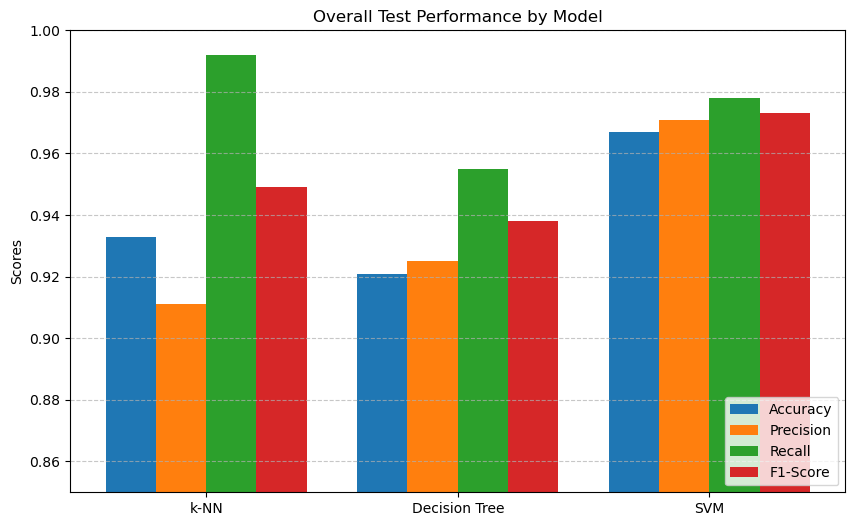

In [6]:
import matplotlib.pyplot as plt
import numpy as np

models = ['k-NN', 'Decision Tree', 'SVM']
metrics = {
    'Accuracy': [0.933, 0.921, 0.967],
    'Precision': [0.911, 0.925, 0.971],
    'Recall': [0.992, 0.955, 0.978],
    'F1-Score': [0.949, 0.938, 0.973]
}

x = np.arange(len(models))
width = 0.2

fig, ax = plt.subplots(figsize=(10, 6))
for i, (metric, values) in enumerate(metrics.items()):
    ax.bar(x + i*width, values, width, label=metric)

ax.set_ylabel('Scores')
ax.set_title('Overall Test Performance by Model')
ax.set_xticks(x + width*1.5)
ax.set_xticklabels(models)
ax.legend(loc='lower right')
plt.ylim(0.85, 1.0) # Zooming in on the high-performance zone
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()